# IADS5 · TP integrador — Ortelana Textil
### Actividad 14 · Laboratorio del modelo final

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 14 · Laboratorio del modelo final

**Qué se espera:** Partiendo del pipeline candidato, ejecutá GridSearchCV con al menos 3 hiperparámetros y 3 valores por parámetro. Reportá configuración, métrica y evaluación final prevista; prepará borrador de README con reproducción y resultados.

**Evidencia a entregar:** GridSearchCV, análisis de errores y README borrador.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Año", "Metros1", "Metros2"]   # sin Sucursal_ID ni Tela_ID (actividad 13)
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]
grupos = train["Sucursal_ID"].astype(str) + "|" + train["Tela_ID"]   # par (Sucursal, Tela), solo para agrupar la CV

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 3) | Test: (657, 3)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GridSearchCV, cross_val_predict, cross_val_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import time

num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline_final(modelo):
    """Solo variables de volumen y año: imputar con la mediana (sin escalar, RF es invariante a la escala).
    Sucursal_ID y Tela_ID no entran al modelo: con un par conocido alcanza con su formato histórico."""
    preprocesador = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median"))]), num_cols),
    ], verbose_feature_names_out=False)
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])

# Pipeline candidato de la actividad 13
pipe_rf = crear_pipeline_final(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))

# El modelo se va a usar con pares (Sucursal, Tela) nuevos: la búsqueda se valida con la CV agrupada por par
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # CV aleatoria, solo como referencia

In [3]:
# 14.1 GridSearchCV: 3 hiperparámetros x 3 valores = 27 combinaciones x 5 folds agrupados por par (solo train)
grilla = {"modelo__n_estimators": [100, 300, 500],
          "modelo__max_features": ["sqrt", 2, 3],   # variables candidatas en cada corte (de 3)
          "modelo__min_samples_leaf": [1, 3, 5]}

busqueda = GridSearchCV(pipe_rf, grilla, cv=cv_grupos, scoring="f1_macro", n_jobs=-1, return_train_score=True)
inicio = time.perf_counter()
busqueda.fit(X_train, y_train, groups=grupos)
print(f"Tiempo de búsqueda: {time.perf_counter() - inicio:.1f} s")
print("Mejor configuración:", busqueda.best_params_)
print(f"Mejor F1 macro CV agrupada (5 folds): {busqueda.best_score_:.4f} ± {busqueda.cv_results_['std_test_score'][busqueda.best_index_]:.4f}")
referencia = cross_val_score(busqueda.best_estimator_, X_train, y_train, cv=cv5, scoring="f1_macro")
print(f"Misma configuración con CV aleatoria (referencia): {referencia.mean():.4f} ± {referencia.std():.4f}")

resultados = pd.DataFrame(busqueda.cv_results_)
columnas = ["param_modelo__n_estimators", "param_modelo__max_features", "param_modelo__min_samples_leaf",
            "mean_train_score", "mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]
resultados[columnas].sort_values("rank_test_score").head(12).round(4)

Tiempo de búsqueda: 18.7 s
Mejor configuración: {'modelo__max_features': 3, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 300}
Mejor F1 macro CV agrupada (5 folds): 0.8868 ± 0.0242


Misma configuración con CV aleatoria (referencia): 0.9094 ± 0.0069


,param_modelo__n_estimators,param_modelo__max_features,param_modelo__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
22,300,3,3,0.9663,0.8868,0.0242,1.1119,1
23,500,3,3,0.9657,0.8845,0.0230,1.7825,2
21,100,3,3,0.9650,0.8841,0.0214,0.4272,3
19,300,3,1,1.0000,0.8841,0.0260,1.0928,4
10,300,2,1,1.0000,0.8837,0.0173,0.9457,5
18,100,3,1,0.9999,0.8834,0.0257,0.3875,6
11,500,2,1,1.0000,0.8832,0.0181,1.7065,7
20,500,3,1,1.0000,0.8825,0.0264,1.7632,8
25,300,3,5,0.9484,0.8811,0.0159,1.1948,9
9,100,2,1,1.0000,0.8810,0.0213,0.2975,10


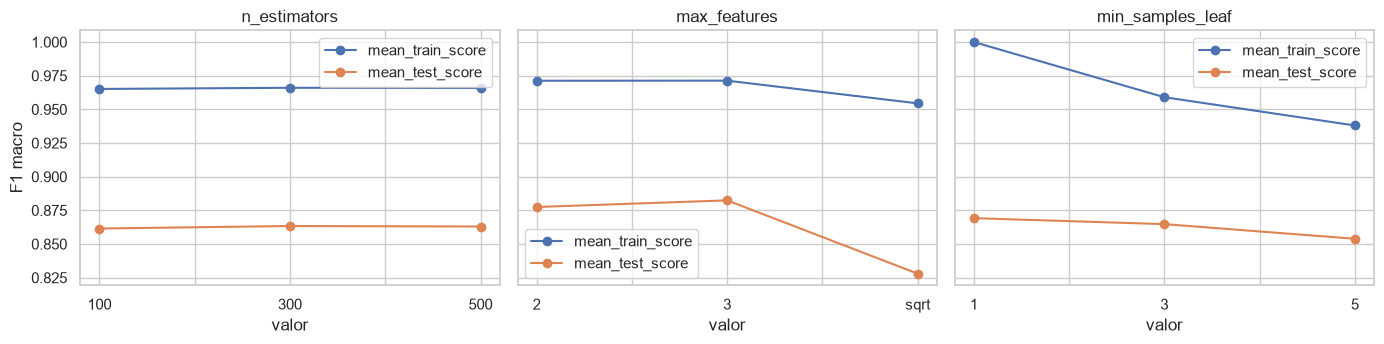

In [4]:
# 14.2 Efecto de cada hiperparámetro (promedio de F1 sobre el resto de la grilla)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, parametro in zip(axes, ["n_estimators", "max_features", "min_samples_leaf"]):
    columna = "param_modelo__" + parametro
    efecto = resultados.groupby(resultados[columna].astype(str))[["mean_train_score", "mean_test_score"]].mean()
    efecto.plot(marker="o", ax=ax)
    ax.set(title=parametro, xlabel="valor", ylabel="F1 macro")
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           B     0.9626    0.9232    0.9425       586
           C     0.8797    0.8924    0.8860       688
           M     0.8202    0.9167    0.8657       612
           S     0.8904    0.8208    0.8541       742

    accuracy                         0.8847      2628
   macro avg     0.8882    0.8883    0.8871      2628
weighted avg     0.8873    0.8847    0.8849      2628



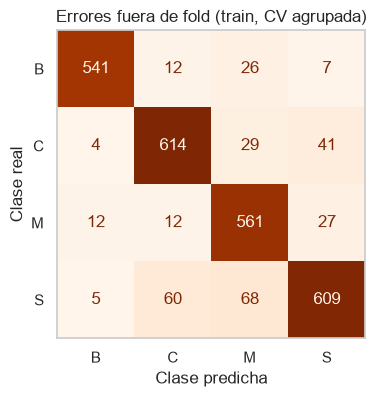

Errores: 303 de 2628 (11.53%)


cantidad
real predicho          
S    M               68
     C               60
C    S               41
     M               29
M    S               27
B    M               26
     C               12
M    B               12
     C               12
B    S                7
S    B                5
C    B                4

,Metros1 mediana (errores),Metros1 mediana (todos)
B,159.44,284.26
C,323.06,1287.31
M,291.82,153.49
S,401.28,1286.94


In [5]:
# 14.3 Análisis de errores con predicciones fuera de fold agrupadas por par (solo train: el test sigue reservado)
mejor_pipe = busqueda.best_estimator_
pred_oof = cross_val_predict(mejor_pipe, X_train, y_train, cv=cv_grupos, groups=grupos, n_jobs=-1)
print(classification_report(y_train, pred_oof, digits=4))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_train, pred_oof, ax=ax, cmap="Oranges", colorbar=False)
ax.set(title="Errores fuera de fold (train, CV agrupada)", xlabel="Clase predicha", ylabel="Clase real")
ax.grid(False)
plt.show()

errores = X_train[y_train != pred_oof].copy()
errores["real"] = y_train[y_train != pred_oof]
errores["predicho"] = pred_oof[y_train != pred_oof]
print(f"Errores: {len(errores)} de {len(X_train)} ({len(errores) / len(X_train):.2%})")
display(errores.groupby(["real", "predicho"]).size().sort_values(ascending=False).rename("cantidad").to_frame())

# ¿Los errores tienen un volumen atípico para su clase real?
pd.DataFrame({"Metros1 mediana (errores)": errores.groupby("real")["Metros1"].median(),
              "Metros1 mediana (todos)": X_train.groupby(y_train)["Metros1"].median()}).round(2)

### Borrador de README

> Borrador preparado en esta actividad. La versión final, con las métricas de test, está en `README.md` (Actividad 15).

**Problema.** Clasificación multiclase de `Format_Reporte` (M mensual, B bimestral, S semestral, C ciclo estacional) a partir de `Año`, `Metros1` y `Metros2`. No se usan `Sucursal_ID` ni `Tela_ID`: el formato es constante por par, así que para un par conocido alcanza con el histórico, y el modelo se destina a pares nuevos. Se excluyen `Metros3`–`Metros12` porque su patrón de faltantes revela la clase. Problema secundario de regresión: `volumen_anual_metros` (suma anual de los metros con dato) a partir de `Sucursal_ID`, `Tela_ID` y `Año`, con `Ridge(alpha=1)`.

**Reproducción.**
1. `python -m pip install -r requirements.txt`
2. Colocar `ventas_historicas_ortelana_argentina.csv` junto a los notebooks.
3. Ejecutar `actividad_01.ipynb` (genera `particion_train_test.csv`) y luego las demás actividades (semilla 42).

**Resultados de selección (solo train, sin test).**
- Modelo candidato: pipeline (imputación con la mediana de `Año`, `Metros1` y `Metros2`, sin escalado porque RF es invariante a la escala) + `RandomForestClassifier`.
- GridSearchCV (CV agrupada por par, 5 folds, F1 macro): `n_estimators=300`, `max_features=3`, `min_samples_leaf=3` → F1 macro CV = 0,8868.
- Evaluación final prevista: un único cálculo de F1 macro, accuracy y matriz de confusión sobre el 20% de test (Actividad 15).

**Pendiente.** Métricas finales de test, serialización (`models/modelo_productivo.joblib`) y script `src/predecir.py`.

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **GridSearchCV:** sobre el pipeline candidato completo (el preprocesamiento queda dentro de cada fold), con **3 hiperparámetros × 3 valores**:
  - `n_estimators` ∈ {100, 300, 500}, para la estabilidad del promedio;
  - `max_features` ∈ {"sqrt", 2, 3}, cuántas de las 3 variables se evalúan en cada corte ("sqrt" equivale a 1);
  - `min_samples_leaf` ∈ {1, 3, 5}, como regularización.
  - Reemplazamos `max_depth` por `max_features` porque, con solo 3 variables, el valor por defecto ("sqrt") obliga a cada corte a usar una única variable elegida al azar, y eso puede limitar al modelo.
- **Validación de la búsqueda:** con la **CV agrupada por par** (`StratifiedGroupKFold`, 5 folds), porque el modelo se va a usar con pares nuevos (Actividad 13). Como referencia, calculamos la misma configuración con la CV aleatoria.
- **Costo:** son 27 combinaciones × 5 folds = 135 ajustes, con F1 macro como scoring.
- **Análisis de errores:** con `cross_val_predict` sobre train, con la misma CV agrupada, para **no tocar el test**.
- **README:** el borrador está en una celda de texto al final de esta actividad; la versión final es `README.md` (Actividad 15).

**Interpretación de los resultados:**
- **Mejor configuración:** `n_estimators=300`, `max_features=3` y `min_samples_leaf=3`, con F1 macro CV agrupada = **0,8868 ± 0,0242**, contra 0,839 del RF por defecto de la Actividad 13 (+0,05). Con la CV aleatoria, la misma configuración da 0,909: la brecha entre ambas es de solo 0,02.
- **Efecto de cada hiperparámetro:**
  - El más influyente es `max_features`: con "sqrt" (1 variable por corte) el promedio es 0,828, con 2 sube a 0,878 y con 3 a 0,882. Con tan pocas variables conviene que cada corte elija la mejor, sobre todo entre `Metros1` y `Metros2`, que se complementan.
  - `min_samples_leaf` = 3 regulariza un poco (train 0,96 en lugar de 1,00) sin perder validación. Con 5 baja a 0,854.
  - `n_estimators` casi no cambia el resultado (0,862–0,863 de promedio); entre las mejores configuraciones, las diferencias son menores a un desvío.
- **Evaluación final prevista:** el test se usará una sola vez, en la Actividad 15, con F1 macro, accuracy, reporte por clase y matriz de confusión.
- **Errores fuera de fold:** 303 de 2.628 (11,5%).
  - Las confusiones más frecuentes son S→M (68), S→C (60), C→S (41), C→M (29), M→S (27) y B→M (26).
  - S es la clase con menor recall (0,82) y M la de menor precision (0,82), porque recibe registros de otras clases.
  - Los errores ocurren cuando el volumen es atípico para la clase real. Por ejemplo, los C y S mal clasificados tienen una mediana de `Metros1` de 323 m y 401 m, contra ~1.287 m de su clase. Los M mal clasificados tienen 292 m, contra 153 m.
  - **S y C se confunden entre sí** (101 errores) porque los dos tienen 2 períodos y volúmenes parecidos: sin el par, el modelo no tiene cómo separarlos cuando el volumen no alcanza.

**Pregunta de análisis:** ¿Qué errores de negocio son más costosos? ¿Qué métrica deberías optimizar?
- **Errores más costosos:** a falta de una definición de negocio, los más costosos son los que **cruzan la granularidad del reporte**: predecir un formato de baja frecuencia (semestral o ciclo estacional, 2 períodos) cuando es de alta frecuencia (mensual o bimestral, 6–12 períodos), o al revés. Implican esperar una estructura de datos distinta, con 2 columnas en lugar de 12.
  - En los errores fuera de fold, 164 de 303 son de este tipo (S→M, C→M, M→S, M→C, B→C…) y 139 ocurren dentro del mismo grupo (S↔C, B↔M).
- **Métrica a optimizar:** como no hay costos documentados ni una clase más importante, optimizamos el **F1 macro**. Pondera las 4 clases por igual y equilibra precision y recall.
  - Si Ortelana definiera una matriz de costos, convendría optimizar el costo esperado (o un F1 ponderado según ese costo) y ajustar los umbrales sobre las probabilidades.

**Limitaciones o mejoras posibles:**
- La grilla no incluyó `max_depth` ni `class_weight`.
- El óptimo está en el borde de la grilla (`max_features=3`, el máximo posible con 3 variables).
- Variables derivadas, como el cociente `Metros2 / Metros1`, podrían ayudar a separar S de C; no las probamos para no alejarnos de las variables del enunciado.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]